#### Does ad reduce preceived wait time?

Training capacity creates three city launch waves at weeks 6, 10, and 14, with 30 cities in each. Another 30 cities stay without access for the study. The schedule is assumed to be set before recent wait trends are known. We evaluate access, including merchants who choose not to use the assistant.

One row is one city's average pickup wait in one week, measured in minutes. We observe 120 cities for 22 weeks. Cities have different starting levels, but their untreated trends are parallel by construction. Effects grow after launch and differ across waves.

Our decision metric is the average change over the first eight weeks of access, event weeks 0 through 7, weighting treated cities equally. This is not an order-weighted national effect. If randomizing the phase-in were feasible, we would prefer that stronger design.

#### data setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Case-study city rollout.
# Cities receive permanent access at weeks 6, 10, or 14; 99 means no access in this study.
rng = np.random.default_rng(27)
cohorts = np.repeat([6, 10, 14, 99], 30)
weeks = np.arange(22)
city_level = rng.normal(0, 0.7, len(cohorts))
noise = np.zeros((len(cohorts), len(weeks)))
for t in weeks:
    noise[:, t] = (0.6 * noise[:, t-1] if t else 0) + rng.normal(0, 0.4, len(cohorts))
# Cohorts differ in LEVELS, but share the same untreated trend.
level = np.select([cohorts == 6, cohorts == 10, cohorts == 14], [0.8, 0.4, 0], default=0.2)
untreated = (7 + city_level[:, None] + level[:, None]
             + 0.025 * weeks + 0.3 * np.sin(weeks / 3) + noise)
event = weeks[None, :] - cohorts[:, None]
multiplier = np.select([cohorts == 6, cohorts == 10, cohorts == 14], [1, 0.7, 1.3], default=0)
true_effect = np.where(event >= 0, -multiplier[:, None] * (0.3 + 0.12 * np.minimum(np.maximum(event, 0), 7)), 0)
wait = untreated + true_effect
df = pd.DataFrame({"city": np.repeat(np.arange(120), 22),
    "week": np.tile(weeks, 120), "first_access_week": np.repeat(cohorts, 22),
    "wait_minutes": wait.ravel()})
df["access"] = (df.week >= df.first_access_week).astype(int)
groups = [6, 10, 14]
event_weeks = np.arange(-4, 8)

def cohort_curve(g, treated_rows, control_rows):
    # A fixed prelaunch baseline. For negative event weeks these are placebo contrasts.
    base = g - 1
    t = g + event_weeks
    treated_change = wait[treated_rows][:, t] - wait[treated_rows][:, [base]]
    control_change = wait[control_rows][:, t] - wait[control_rows][:, [base]]
    return treated_change.mean(axis=0) - control_change.mean(axis=0)

control_rows = np.flatnonzero(cohorts == 99)
curves = np.array([cohort_curve(g, np.flatnonzero(cohorts == g), control_rows) for g in groups])
# Equal-size cohorts and a common follow-up window: the composition stays fixed.
effect = curves.mean(axis=0)

#### 1. Inspect the rollout and choose the supported horizon

Before estimating anything, inspect the rows and launch dates. The last wave has eight postlaunch weeks, so using a common eight-week horizon keeps all three waves in every comparison.

Raw city-week rows:
 city  week  first_access_week  wait_minutes  access
    0     0                  6          8.47       0
    0     1                  6          8.75       0
    0     2                  6          8.53       0
    0     3                  6          8.88       0
    0     4                  6          8.47       0
    0     5                  6          8.80       0
    0     6                  6          9.15       1
    0     7                  6          8.76       1


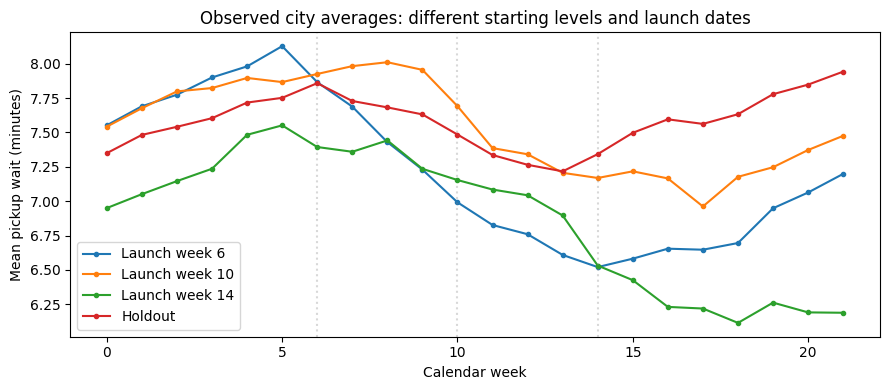

,Cohort,Cities,Weeks observed per city,Postlaunch weeks available
0,Week 6,30,22,16
1,Week 10,30,22,12
2,Week 14,30,22,8
3,Holdout,30,22,0


In [2]:
print("Raw city-week rows:")
print(df.head(8).round(2).to_string(index=False))
# Plot observed cohort averages in calendar time before adjusting anything.
fig, ax = plt.subplots(figsize=(9, 4))
for g in [6, 10, 14, 99]:
    label = f"Launch week {g}" if g != 99 else "Holdout"
    ax.plot(weeks, wait[cohorts == g].mean(axis=0), marker=".", label=label)
    if g != 99:
        ax.axvline(g, color="gray", alpha=0.3, linestyle=":")
ax.set(xlabel="Calendar week", ylabel="Mean pickup wait (minutes)",
       title="Observed city averages: different starting levels and launch dates")
ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"Cohort": ["Week 6", "Week 10", "Week 14", "Holdout"],
    "Cities": [30, 30, 30, 30], "Weeks observed per city": [22]*4,
    "Postlaunch weeks available": [16, 12, 8, 0]})

The table shows 30 cities per cohort. Early cities have 16 postlaunch weeks, the middle wave has 12, and the last wave has 8. Reporting all available horizons would eventually leave only early cities in the average.

The lines show observed cohort means, not causal effects. Their different heights are not themselves a DiD failure. We need credible untreated changes, and the rollout schedule must not follow unobserved changes in pickup waits.

#### 2. Build cohort comparisons before averaging

Start with the week-10 cohort at calendar week 13. Measure its change from week 9, subtract the holdout cities' change over those same dates, and label the result event week 3.

For this walkthrough, use the 30 holdout cities throughout. Later-launching cities could also be eligible before they adopt, but we do not need them here. Using a fixed control population keeps the calculation easy to inspect and avoids already-treated comparisons.

         Group  Week 9  Week 13  Change
Week-10 cities   7.955    7.206  -0.749
Holdout cities   7.631    7.217  -0.414
DiD at event week 3: -0.335 minutes


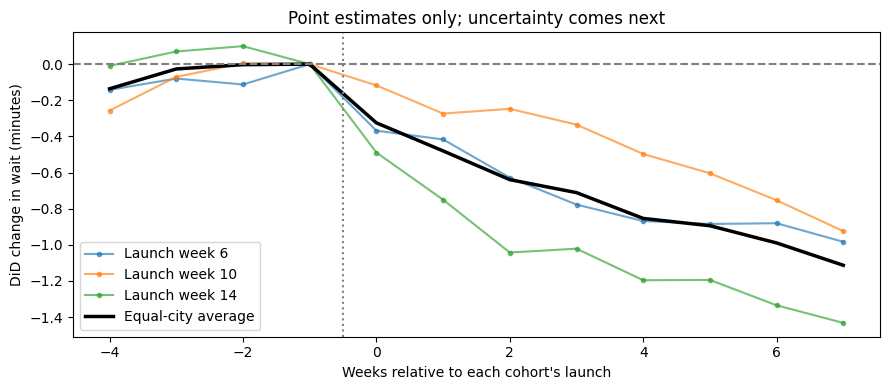

,Event week,Cohort 6,Cohort 10,Cohort 14,Equal-city average
0,-4,-0.142,-0.257,-0.010,-0.136
1,-3,-0.080,-0.070,0.070,-0.027
2,-2,-0.113,0.004,0.100,-0.003
3,-1,0.000,0.000,0.000,0.000
4,0,-0.368,-0.117,-0.489,-0.325
5,1,-0.417,-0.274,-0.750,-0.480
6,2,-0.628,-0.247,-1.043,-0.639
7,3,-0.777,-0.335,-1.021,-0.711
8,4,-0.868,-0.497,-1.196,-0.854
9,5,-0.885,-0.604,-1.194,-0.894


In [3]:
# Work through one cohort at one calendar date before pooling.
g, t = 10, 13
treated = cohorts == g
control = cohorts == 99
baseline = g - 1
comparison = pd.DataFrame({
    "Group": ["Week-10 cities", "Holdout cities"],
    "Week 9": [wait[treated, baseline].mean(), wait[control, baseline].mean()],
    "Week 13": [wait[treated, t].mean(), wait[control, t].mean()]})
comparison["Change"] = comparison["Week 13"] - comparison["Week 9"]
print(comparison.round(3).to_string(index=False))
print(f"DiD at event week 3: {comparison.Change.iloc[0] - comparison.Change.iloc[1]:.3f} minutes")

# Use the same three cohorts at each event week. Week -1 is the reference.
fig, ax = plt.subplots(figsize=(9, 4))
for g, curve in zip(groups, curves):
    ax.plot(event_weeks, curve, marker=".", alpha=0.65, label=f"Launch week {g}")
ax.plot(event_weeks, effect, color="black", linewidth=2.5, label="Equal-city average")
ax.axhline(0, color="gray", linestyle="--")
ax.axvline(-0.5, color="gray", linestyle=":")
ax.set(xlabel="Weeks relative to each cohort's launch", ylabel="DiD change in wait (minutes)",
       title="Point estimates only; uncertainty comes next")
ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"Event week": event_weeks,
    "Cohort 6": curves[0], "Cohort 10": curves[1], "Cohort 14": curves[2],
    "Equal-city average": effect}).round(3)

The cohort estimates differ because the benefit set in the data setup differs across waves. The equal-city average is about −0.325 minutes at launch and −1.113 minutes at event week 7. Negative means a shorter wait.

All three waves contribute at every plotted event week. That makes the growing average more interpretable than a curve whose cohort mix changes along the way. Week −1 is zero by construction because it is the reference, not because a test established parallel trends.

These are still point estimates. Next, check whether the prelaunch differences look concerning and how much uncertainty surrounds the postlaunch pattern.

#### 3. Check prelaunch patterns and quantify the result

Weekly observations from the same city are related. We therefore resample whole cities with their complete histories, rather than treating 2,640 city-week rows as independent observations. We also reuse the same resampled holdout cities across cohort calculations so their shared uncertainty is preserved.

The event-study chart uses a 95% simultaneous band: it accounts for inspecting the whole plotted path, not just one selected week. We separately report a 95% interval for the predefined eight-week average. Both rely on enough independent cities and the stated comparison design.

Joint prelaunch check p-value: 0.222
Week -1 is the chosen reference, not evidence of a zero pretrend.
 Event week  Estimate  95% band lower  95% band upper
         -4    -0.136          -0.361           0.089
         -3    -0.027          -0.219           0.165
         -2    -0.003          -0.162           0.156
         -1     0.000           0.000           0.000
          0    -0.325          -0.511          -0.139
          1    -0.480          -0.697          -0.264
          2    -0.639          -0.855          -0.423
          3    -0.711          -0.952          -0.470
          4    -0.854          -1.132          -0.576
          5    -0.894          -1.188          -0.600
          6    -0.990          -1.289          -0.690
          7    -1.113          -1.424          -0.802


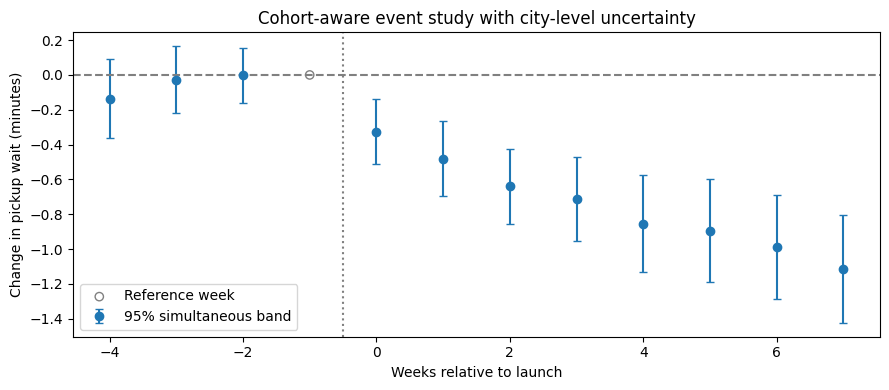

,Metric,Estimate,Bootstrap SE,95% lower,95% upper,p-value (normal approximation),Average set in the data setup
0,"Average wait change, event weeks 0-7 (minutes)",-0.751,0.078,-0.903,-0.599,4.01e-22,-0.72


In [4]:
# Bootstrap whole cities, not city-week rows: outcomes within a city are related.
# Keep cohort sizes fixed and reuse the same control sample across cohort estimates.
boot_rng = np.random.default_rng(2026)
draws = []
for b in range(999):
    controls = boot_rng.choice(control_rows, len(control_rows), replace=True)
    cohort_draws = []
    for g in groups:
        members = np.flatnonzero(cohorts == g)
        sampled = boot_rng.choice(members, len(members), replace=True)
        cohort_draws.append(cohort_curve(g, sampled, controls))
    draws.append(np.mean(cohort_draws, axis=0))
draws = np.array(draws)
se = draws.std(axis=0, ddof=1)
# A simultaneous band accounts for examining the whole plotted event path.
# Exclude the reference week: its zero is fixed, not estimated.
active = event_weeks != -1
max_t = np.max(np.abs((draws[:, active] - effect[active]) / se[active]), axis=1)
critical = np.quantile(max_t, 0.95)
lower, upper = effect - critical * se, effect + critical * se
# Joint prelaunch check, not a proof of postlaunch parallel trends.
pre = event_weeks < -1
pre_stat = np.max(np.abs(effect[pre] / se[pre]))
pre_boot = np.max(np.abs((draws[:, pre] - effect[pre]) / se[pre]), axis=1)
pre_p = (1 + np.sum(pre_boot >= pre_stat)) / (len(draws) + 1)
print(f"Joint prelaunch check p-value: {pre_p:.3f}")
print("Week -1 is the chosen reference, not evidence of a zero pretrend.")
print(pd.DataFrame({"Event week": event_weeks, "Estimate": effect,
                    "95% band lower": lower, "95% band upper": upper}).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(event_weeks[active], effect[active],
            yerr=critical * se[active], fmt="o", capsize=3, label="95% simultaneous band")
ax.scatter([-1], [0], facecolors="none", edgecolors="gray", label="Reference week")
ax.axhline(0, color="gray", linestyle="--")
ax.axvline(-0.5, color="gray", linestyle=":")
ax.set(xlabel="Weeks relative to launch", ylabel="Change in pickup wait (minutes)",
       title="Cohort-aware event study with city-level uncertainty")
ax.legend()
plt.tight_layout()
plt.show()

# Predefine one business summary: equal weight to 90 treated cities and weeks 0-7.
post = event_weeks >= 0
average = effect[post].mean()
average_se = draws[:, post].mean(axis=1).std(ddof=1)
p_value = 2 * norm.sf(abs(average / average_se))
pd.DataFrame([{"Metric": "Average wait change, event weeks 0-7 (minutes)",
    "Estimate": round(average, 3), "Bootstrap SE": round(average_se, 3),
    "95% lower": round(average - 1.96 * average_se, 3),
    "95% upper": round(average + 1.96 * average_se, 3),
    "p-value (normal approximation)": f"{p_value:.2e}",
    "Average set in the data setup": -0.72}])

$Before launch$: the joint check has p = 0.222. We do not see a clear warning in the three estimated prelaunch contrasts. That is not proof of parallel trends; modest deviations can be hard to detect, and launch timing still needs a credible explanation.

$After launch$: the city-weighted average pickup wait is 0.751 minutes lower across event weeks 0–7, about 45 seconds. Its 95% interval is a reduction of 0.599 to 0.903 minutes. The average set in the data setup reduction is 0.72 minutes, which falls inside that interval.

The average-effect p-value is below 0.001 using the bootstrap standard error and a normal approximation, against a prespecified 5% significance level. The postlaunch event-study bands also lie below zero. This supports a reduction under the design assumptions, not a guarantee that every city improves or that longer-term effects are identical.

#### Recommendations: 

this is promising enough to evaluate expansion to similar cities. First check whether 45 seconds matters operationally and whether cancellations, late orders, and merchant burden stayed within agreed guardrails. Those outcomes are not supplied here. If they look healthy and the rollout audit holds up, expand in measured waves while preserving a comparison for longer-term effects.

#### What does this implementation cover?
This is a transparent, unadjusted group-time DiD for a balanced panel with an untreated holdout and a fixed cohort mix. It allows different cohort effects and preserves within-city dependence in the bootstrap. It assumes cities are independent; shared regional shocks would require revisiting the clustering level.

For covariate adjustment, changing control groups, attrition, or more complex treatment histories, use a method designed for that setting. Do not treat this short implementation as a replacement for all features of a modern DiD package.